In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import scipy.io
import matplotlib.pyplot as plt
import os
import sys

import STitch3D

import warnings

warnings.filterwarnings("ignore")

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

In [2]:
mat = scipy.io.mmread(r"C:\Code\Data\DLPFC\GSE144136_GeneBarcodeMatrix_Annotated.mtx")
meta = pd.read_csv(r"C:\Code\Data\DLPFC\GSE144136_CellNames.csv", index_col=0)
meta.index = meta.x.values
group = [i.split('.')[1].split('_')[0] for i in list(meta.x.values)]
condition = [i.split('.')[1].split('_')[1] for i in list(meta.x.values)]
celltype = [i.split('.')[0] for i in list(meta.x.values)]
meta["group"] = group
meta["condition"] = condition
meta["celltype"] = celltype
genename = pd.read_csv(r"C:\Code\Data\DLPFC\GSE144136_GeneNames.csv", index_col=0)
genename.index = genename.x.values
adata_ref = ad.AnnData(X=mat.tocsr().T)
adata_ref.obs = meta
adata_ref.var = genename
adata_ref = adata_ref[adata_ref.obs.condition.values.astype(str) == "Control", :]

In [3]:
#spatial data
anno_df = pd.read_csv(r"C:\Code\Data\DLPFC\barcode_level_layer_map.tsv", sep='\t', header=None)
# [151507, 151508, 151509, 151510], [151669, 151670, 151671, 151672],[151673, 151674, 151675, 151676]
slice_idx = [151507, 151508, 151509, 151510]

adata_st1 = sc.read_visium(path="C:\Code\Data\DLPFC/%d" % slice_idx[0],
                           count_file="filtered_feature_bc_matrix.h5")
anno_df1 = anno_df.iloc[anno_df[1].values.astype(str) == str(slice_idx[0])]
anno_df1.columns = ["barcode", "slice_id", "layer"]
anno_df1.index = anno_df1['barcode']
adata_st1.obs = adata_st1.obs.join(anno_df1, how="left")
adata_st1 = adata_st1[adata_st1.obs['layer'].notna()]

adata_st2 = sc.read_visium(path="C:\Code\Data\DLPFC/%d" % slice_idx[1],
                           count_file="filtered_feature_bc_matrix.h5")
anno_df2 = anno_df.iloc[anno_df[1].values.astype(str) == str(slice_idx[1])]
anno_df2.columns = ["barcode", "slice_id", "layer"]
anno_df2.index = anno_df2['barcode']
adata_st2.obs = adata_st2.obs.join(anno_df2, how="left")
adata_st2 = adata_st2[adata_st2.obs['layer'].notna()]

adata_st3 = sc.read_visium(path="C:\Code\Data\DLPFC/%d" % slice_idx[2],
                           count_file="filtered_feature_bc_matrix.h5")
anno_df3 = anno_df.iloc[anno_df[1].values.astype(str) == str(slice_idx[2])]
anno_df3.columns = ["barcode", "slice_id", "layer"]
anno_df3.index = anno_df3['barcode']
adata_st3.obs = adata_st3.obs.join(anno_df3, how="left")
adata_st3 = adata_st3[adata_st3.obs['layer'].notna()]

adata_st4 = sc.read_visium(path="C:\Code\Data\DLPFC/%d" % slice_idx[3],
                           count_file="filtered_feature_bc_matrix.h5")
anno_df4 = anno_df.iloc[anno_df[1].values.astype(str) == str(slice_idx[3])]
anno_df4.columns = ["barcode", "slice_id", "layer"]
anno_df4.index = anno_df4['barcode']
adata_st4.obs = adata_st4.obs.join(anno_df4, how="left")
adata_st4 = adata_st4[adata_st4.obs['layer'].notna()]

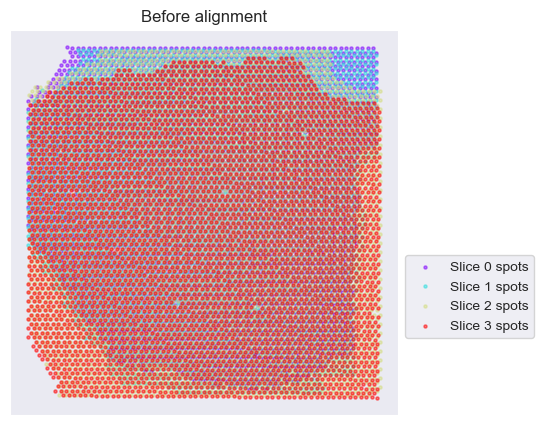

Using the Iterative Closest Point algorithm for alignemnt.
Detecting edges...
Aligning edges...


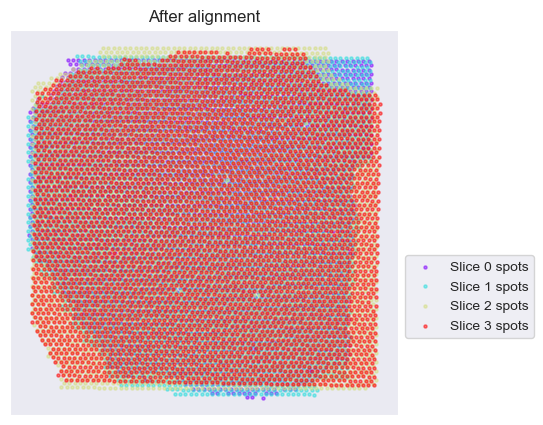

In [4]:
adata_st_list_raw = [adata_st1, adata_st2, adata_st3, adata_st4]
adata_st_list = STitch3D.utils.align_spots(adata_st_list_raw, plot=True)

In [5]:
celltype_list_use = ['Astros_1', 'Astros_2', 'Astros_3', 'Endo', 'Micro/Macro',
                     'Oligos_1', 'Oligos_2', 'Oligos_3',
                     'Ex_1_L5_6', 'Ex_2_L5', 'Ex_3_L4_5', 'Ex_4_L_6', 'Ex_5_L5',
                     'Ex_6_L4_6', 'Ex_7_L4_6', 'Ex_8_L5_6', 'Ex_9_L5_6', 'Ex_10_L2_4']

adata_st, adata_basis = STitch3D.utils.preprocess(adata_st_list,
                                                  adata_ref,
                                                  celltype_ref=celltype_list_use,
                                                  sample_col="group",
                                                  slice_dist_micron=[10., 300., 10.],
                                                  n_hvg_group=500)

Finding highly variable genes...
4558 highly variable genes selected.
Calculate basis for deconvolution...
1 batches are used for computing the basis vector of cell type <Astros_1>.
17 batches are used for computing the basis vector of cell type <Astros_2>.
14 batches are used for computing the basis vector of cell type <Astros_3>.
17 batches are used for computing the basis vector of cell type <Endo>.
17 batches are used for computing the basis vector of cell type <Ex_10_L2_4>.
15 batches are used for computing the basis vector of cell type <Ex_1_L5_6>.
15 batches are used for computing the basis vector of cell type <Ex_2_L5>.
17 batches are used for computing the basis vector of cell type <Ex_3_L4_5>.
14 batches are used for computing the basis vector of cell type <Ex_4_L_6>.
17 batches are used for computing the basis vector of cell type <Ex_5_L5>.
16 batches are used for computing the basis vector of cell type <Ex_6_L4_6>.
16 batches are used for computing the basis vector of cell 

In [6]:
model = STitch3D.model.Model(adata_st, adata_basis)

model.train()

  0%|          | 2/20000 [00:00<2:18:37,  2.40it/s]

Step: 0, Loss: 1986.0793, d_loss: 1980.7177, f_loss: 53.6175


 10%|█         | 2002/20000 [06:58<1:01:26,  4.88it/s]

Step: 2000, Loss: 990.8552, d_loss: 987.2393, f_loss: 36.1586


 20%|██        | 4001/20000 [14:04<1:09:12,  3.85it/s]

...

 80%|████████  | 16001/20000 [57:21<15:09,  4.40it/s]

Step: 16000, Loss: 959.3210, d_loss: 955.7797, f_loss: 35.4132


 90%|█████████ | 18002/20000 [1:04:29<07:01,  4.74it/s]

Step: 18000, Loss: 959.3735, d_loss: 955.8276, f_loss: 35.4593


100%|██████████| 20000/20000 [1:11:35<00:00,  4.66it/s]


In [7]:
result = model.eval(adata_st_list_raw, save=True)

In [8]:
from sklearn.mixture import GaussianMixture

np.random.seed(1234)
gm = GaussianMixture(n_components=7, covariance_type='tied', init_params='kmeans')
y = gm.fit_predict(model.adata_st.obsm['latent'], y=None)
model.adata_st.obs["GM"] = y

# 重新排序集群标签
order = [2, 4, 6, 0, 3, 5, 1]  # 重新排序集群标签
model.adata_st.obs["Cluster"] = [order[label] for label in model.adata_st.obs["GM"].values]

# 直接将标签分配给结果中的对应位置，而不是尝试通过索引匹配
for i in range(len(result)):
    # 确保索引正确匹配或使用替代方法分配标签
    result[i].obs["GM"] = model.adata_st.obs["GM"].values[
        model.adata_st.obs["slice_id"] == result[i].obs["slice_id"][0]].copy()
    result[i].obs["Cluster"] = model.adata_st.obs["Cluster"].values[
        model.adata_st.obs["slice_id"] == result[i].obs["slice_id"][0]].copy()

Slice 151507 spatial domain detection result:


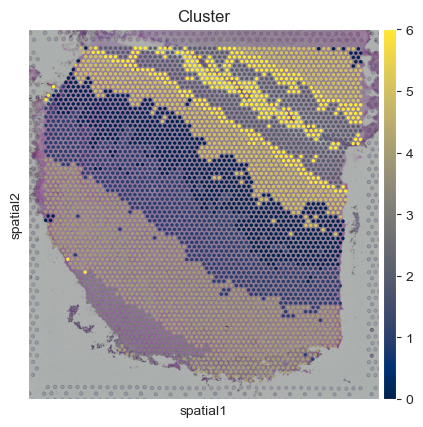

Slice 151508 spatial domain detection result:


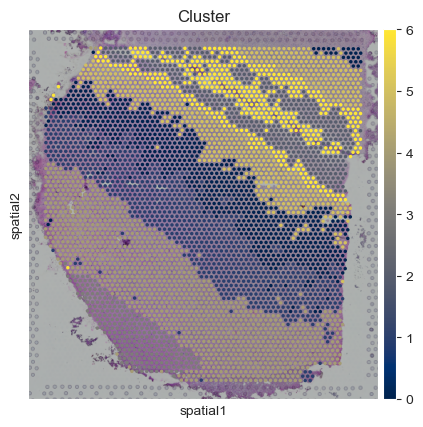

Slice 151509 spatial domain detection result:


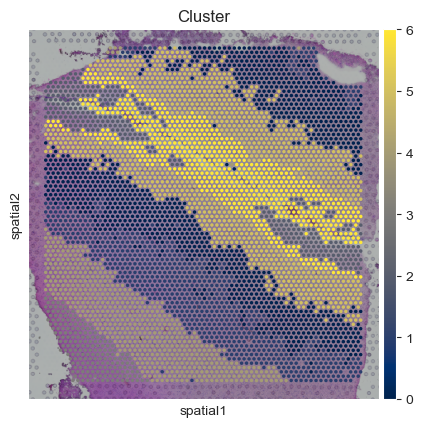

Slice 151510 spatial domain detection result:


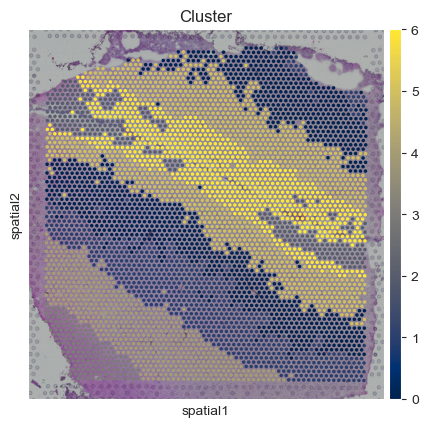

In [9]:
for i, adata_st_i in enumerate(result):
    print("Slice %d spatial domain detection result:" % slice_idx[i])
    sc.pl.spatial(adata_st_i, img_key="lowres", color="Cluster", color_map="cividis", size=1.)

Slice 151507 cell-type deconvolution result:


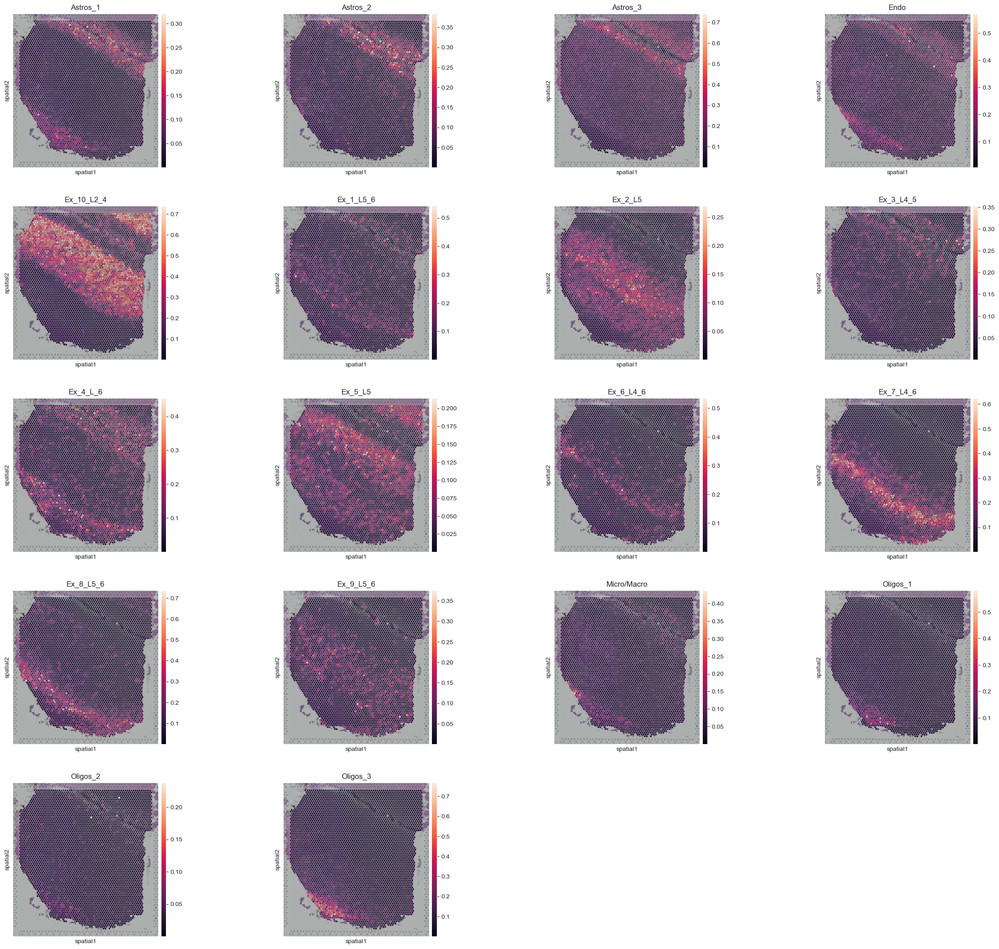

Slice 151508 cell-type deconvolution result:


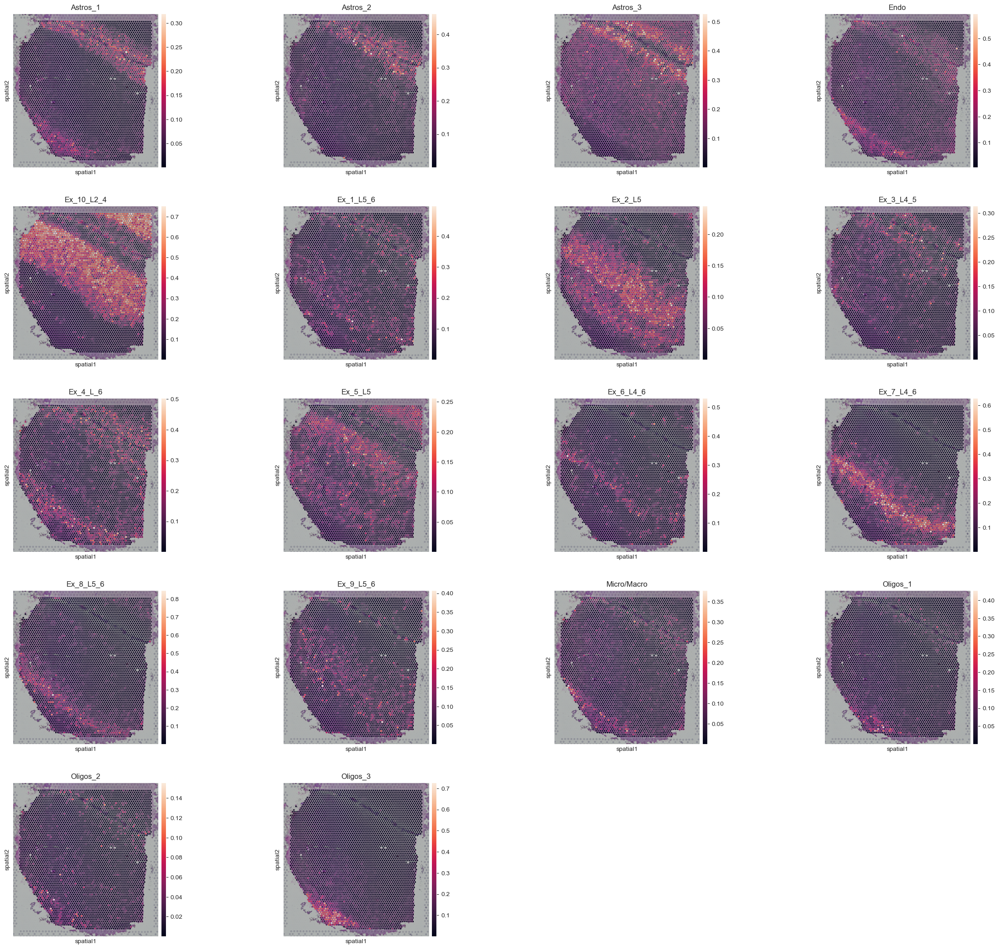

Slice 151509 cell-type deconvolution result:


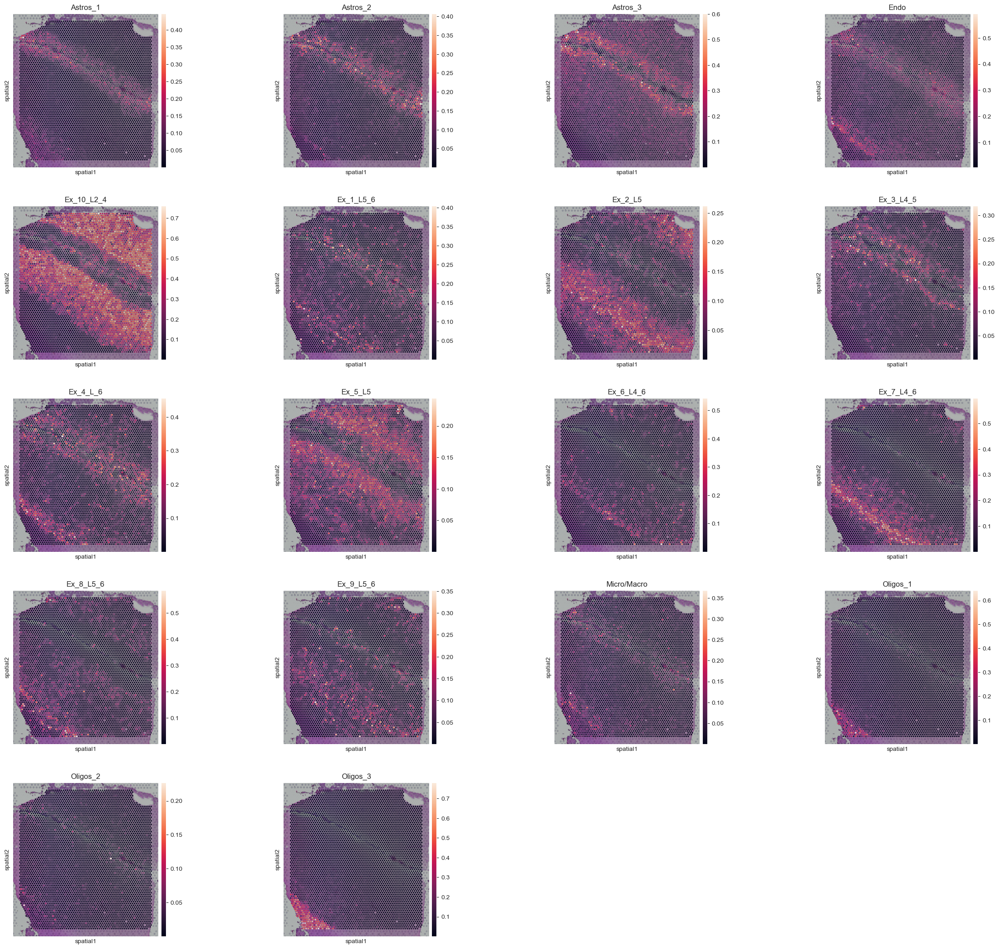

Slice 151510 cell-type deconvolution result:


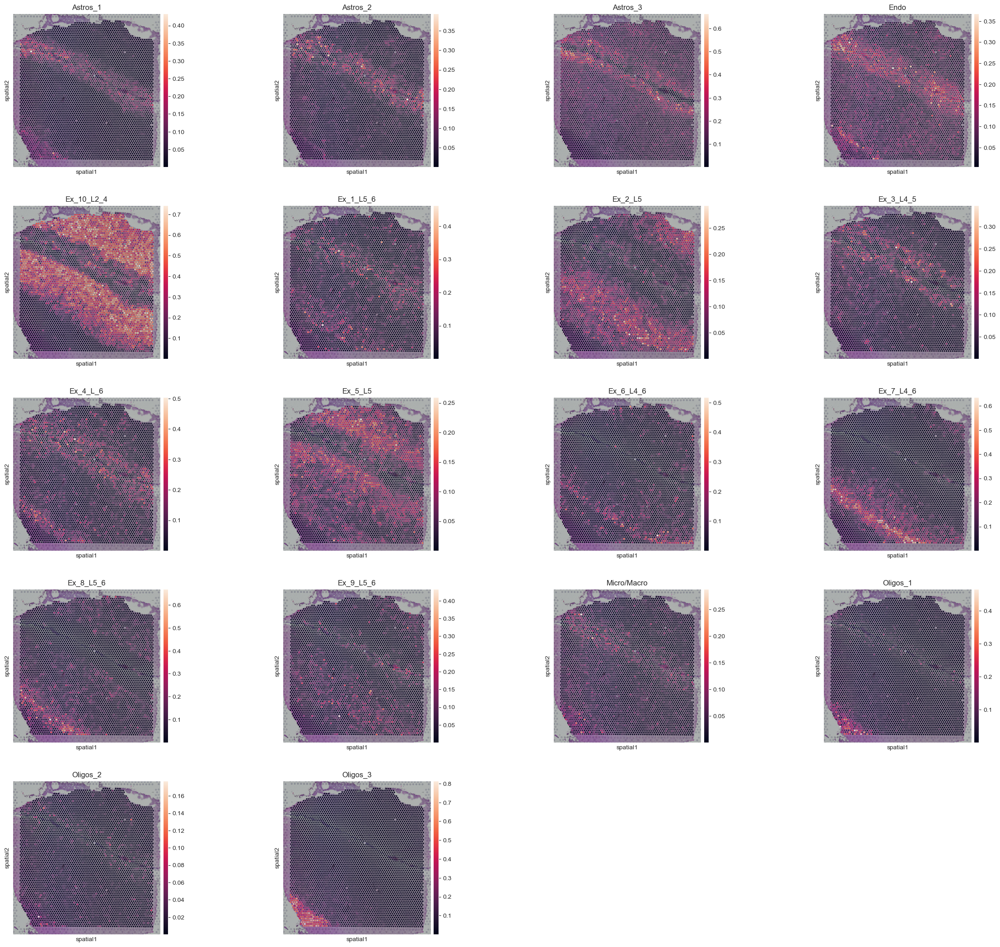

In [10]:
for i, adata_st_i in enumerate(result):
    print("Slice %d cell-type deconvolution result:" % slice_idx[i])
    sc.pl.spatial(adata_st_i, img_key="lowres", color=list(adata_basis.obs.index), size=1.)

In [11]:
import umap

reducer = umap.UMAP(n_neighbors=30,
                    n_components=2,
                    metric="correlation",
                    n_epochs=None,
                    learning_rate=1.0,
                    min_dist=0.3,
                    spread=1.0,
                    set_op_mix_ratio=1.0,
                    local_connectivity=1,
                    repulsion_strength=1,
                    negative_sample_rate=5,
                    a=None,
                    b=None,
                    random_state=1234,
                    metric_kwds=None,
                    angular_rp_forest=False,
                    verbose=True)

embedding = reducer.fit_transform(model.adata_st.obsm['latent'])

n_spots = embedding.shape[0]
size = 120000 / n_spots

UMAP(angular_rp_forest=True, local_connectivity=1, metric='correlation', min_dist=0.3, n_jobs=1, n_neighbors=30, random_state=1234, repulsion_strength=1, verbose=True)
Wed Jul 16 21:29:39 2025 Construct fuzzy simplicial set
Wed Jul 16 21:29:39 2025 Finding Nearest Neighbors
Wed Jul 16 21:29:39 2025 Building RP forest with 12 trees
Wed Jul 16 21:29:42 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	Stopping threshold met -- exiting after 3 iterations
Wed Jul 16 21:29:52 2025 Finished Nearest Neighbor Search
Wed Jul 16 21:29:54 2025 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Wed Jul 16 21:30:03 2025 Finished embedding


In [12]:
model.adata_st.obsm["X_umap"] = embedding
sc.pp.neighbors(model.adata_st, use_rep='latent')
sc.tl.paga(model.adata_st, groups='layer')

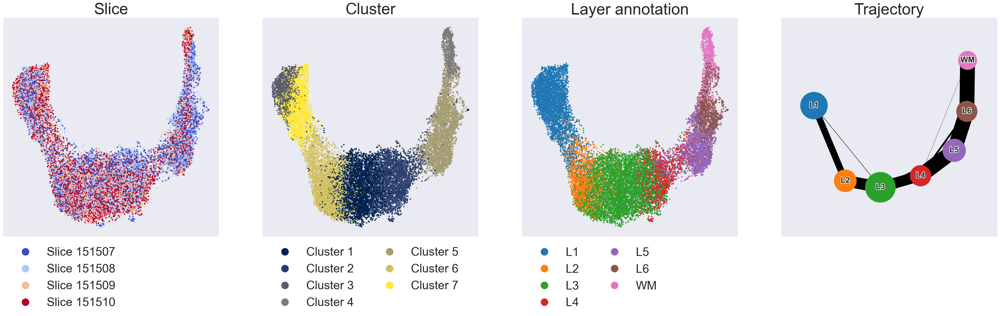

In [13]:
from sklearn import preprocessing
from matplotlib.colors import ListedColormap

le_slice = preprocessing.LabelEncoder()
label_slice = le_slice.fit_transform(model.adata_st.obs['slice_id'])

le_layer = preprocessing.LabelEncoder()
label_layer = le_layer.fit_transform(model.adata_st.obs['layer'])

np.random.seed(1234)
order = np.arange(n_spots)
np.random.shuffle(order)

f = plt.figure(figsize=(45, 10))

ax1 = f.add_subplot(1, 4, 1)
scatter1 = ax1.scatter(embedding[order, 0], embedding[order, 1],
                       s=size, c=label_slice[order], cmap='coolwarm')
ax1.set_title("Slice", fontsize=40)
ax1.tick_params(axis='both', bottom=False, top=False, left=False, right=False, labelleft=False, labelbottom=False,
                grid_alpha=0)

l1 = ax1.legend(handles=scatter1.legend_elements()[0],
                labels=["Slice %d" % i for i in slice_idx],
                loc="upper left", bbox_to_anchor=(0., 0.),
                markerscale=3., title_fontsize=45, fontsize=30, frameon=False, ncol=1)
l1._legend_box.align = "left"

ax2 = f.add_subplot(1, 4, 2)
scatter2 = ax2.scatter(embedding[order, 0], embedding[order, 1],
                       s=size, c=model.adata_st.obs['Cluster'][order], cmap='cividis')
ax2.set_title("Cluster", fontsize=40)
ax2.tick_params(axis='both', bottom=False, top=False, left=False, right=False, labelleft=False, labelbottom=False,
                grid_alpha=0)

l2 = ax2.legend(handles=scatter2.legend_elements()[0],
                labels=["Cluster %d" % i for i in range(1, 8)],
                loc="upper left", bbox_to_anchor=(0., 0.),
                markerscale=3., title_fontsize=45, fontsize=30, frameon=False, ncol=2)

l2._legend_box.align = "left"

ax3 = f.add_subplot(1, 4, 3)
scatter3 = ax3.scatter(embedding[order, 0], embedding[order, 1],
                       s=size, c=label_layer[order], cmap=ListedColormap(
        ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]))
ax3.set_title("Layer annotation", fontsize=40)
ax3.tick_params(axis='both', bottom=False, top=False, left=False, right=False, labelleft=False, labelbottom=False,
                grid_alpha=0)

l3 = ax3.legend(handles=scatter3.legend_elements()[0],
                labels=sorted(set(adata_st.obs['layer'].values)),
                loc="upper left", bbox_to_anchor=(0., 0.),
                markerscale=3., title_fontsize=45, fontsize=30, frameon=False, ncol=2)

l3._legend_box.align = "left"

ax4 = f.add_subplot(1, 4, 4)
ax4.set_title("Trajectory", fontsize=40)
ax4.tick_params(axis='both', bottom=False, top=False, left=False, right=False, labelleft=False, labelbottom=False,
                grid_alpha=0)
ax4.set_xlim(ax3.get_xlim())
ax4.set_ylim(ax3.get_ylim())

pos = []
for layer in ["L1", "L2", "L3", "L4", "L5", "L6", "WM"]:
    # for layer in [ "L3", "L4", "L5", "L6", "WM"]:
    center = np.mean(embedding[model.adata_st.obs['layer'].values.astype(str) == layer, :], axis=0)
    pos.append(center)

sc.pp.neighbors(model.adata_st, use_rep='latent')
sc.tl.paga(model.adata_st, groups='layer')
sc.pl.paga(adata_st, pos=np.array(pos), node_size_scale=20, edge_width_scale=5, fontsize=20, fontoutline=3, ax=ax4)

f.subplots_adjust(hspace=.1, wspace=.1)
plt.show()

In [14]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import harmonypy as hm


def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }


metrics_results = []
for i, adata_st_i in enumerate(result):
    # Compute metrics for the current slice
    metrics = compute_metrics(adata_st_i, 'layer', 'Cluster')

    # Store results for later saving
    metrics_results.append({
        'Slice': slice_idx[i],
        **metrics
    })

    # Print metrics for the current slice
    print(f"\nSlice {slice_idx[i]}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:}")


Slice 151507:
ARI: 0.43935089460735016
NMI: 0.6459587367516845
HOM: 0.6458563146394593
COM: 0.6460611913539626
CHAOS: 0.057002668651841656
PAS: 0.08078654347311064

Slice 151508:
ARI: 0.4302532439404095
NMI: 0.6223102220302147
HOM: 0.6350446783379573
COM: 0.6100764498871216
CHAOS: 0.056554794307756576
PAS: 0.08057521113900935

Slice 151509:
ARI: 0.46369001969938217
NMI: 0.6398324561963434
HOM: 0.6794961027952372
COM: 0.6045439289303861
CHAOS: 0.05473637308909533
PAS: 0.0797827903091061

Slice 151510:
ARI: 0.44114458797846384
NMI: 0.6261804013434861
HOM: 0.6636998930263723
COM: 0.5926759505645983
CHAOS: 0.05604193495272616
PAS: 0.08030467899891186


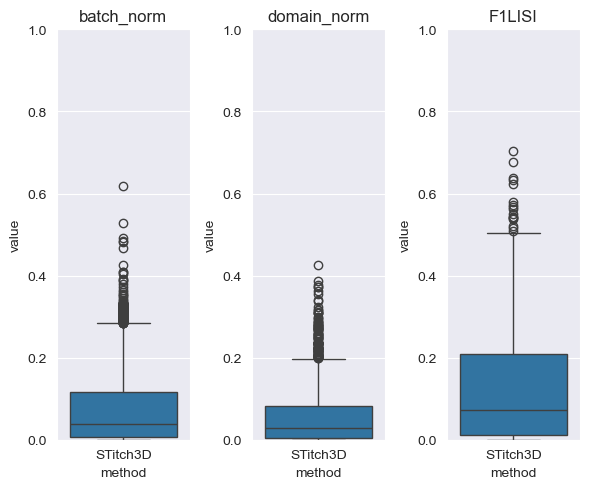

In [15]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1) / num_batchs
    norm_domain = (LISI_domain_norm - 1) / num_domains
    LISI = 2 * (1 - norm_domain) * norm_batch / (1 - norm_domain + norm_batch)
    return LISI, norm_batch, norm_domain


LISI, norm_batch, norm_domain = compute_fscoreLISI(model.adata_st, 'latent', 'layer', 'Cluster')

df_batch_norm = pd.DataFrame({
    'method': 'STitch3D',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STitch3D',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STitch3D',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

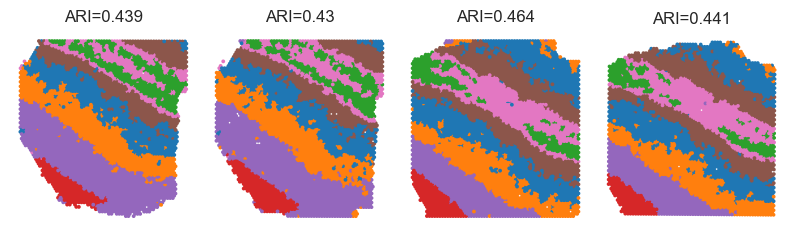

In [16]:
spot_size = 200
title_size = 12
ARI_list = []
from sklearn.metrics import adjusted_rand_score as ari_score

for i, adata_st_i in enumerate(result):
    ARI_list.append(round(ari_score(adata_st_i.obs['layer'], adata_st_i.obs['Cluster']), 3))
fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})

for i, adata_st_i in enumerate(result):
    adata_st_i.obs['NCluster'] = adata_st_i.obs['Cluster'].astype(str)
    _sc_ = sc.pl.spatial(adata_st_i, img_key=None, color=['NCluster'], title=[''],
                         legend_loc=None, legend_fontsize=12, show=False, ax=ax[i], frameon=False,
                         spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[i]), size=title_size)

In [17]:
file_name = 'STitch3D_Donor1.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'
adata_st.obs['slice_id'] = adata_st.obs['slice_id'].astype(float).astype(int).astype(str).astype('category')
adata_st.write(file_path)

In [18]:
print(adata_st)

AnnData object with n_obs × n_vars = 17985 × 4558
    obs: 'in_tissue', 'array_row', 'array_col', 'barcode', 'slice_id', 'layer', 'slice', 'batch', 'library_size', 'GM', 'Cluster'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p', 'neighbors', 'paga', 'layer_sizes', 'layer_colors'
    obsm: 'spatial', 'spatial_aligned', 'count', 'graph', '3D_coor', 'latent', 'X_umap'
    obsp: 'distances', 'connectivities'


In [19]:
print(adata_st.obs['slice_id'])

AAACAACGAATAGTTC-1-slice0    151507
AAACAAGTATCTCCCA-1-slice0    151507
AAACAATCTACTAGCA-1-slice0    151507
AAACACCAATAACTGC-1-slice0    151507
AAACAGCTTTCAGAAG-1-slice0    151507
                              ...  
TTGTTTCACATCCAGG-1-slice3    151510
TTGTTTCATTAGTCTA-1-slice3    151510
TTGTTTCCATACAACT-1-slice3    151510
TTGTTTGTATTACACG-1-slice3    151510
TTGTTTGTGTAAATTC-1-slice3    151510
Name: slice_id, Length: 17985, dtype: category
Categories (4, object): ['151507', '151508', '151509', '151510']
